# 酒店预订取消行为分析

**Python 探索性数据分析｜Hotel Booking Demand**

选取两家酒店的 119,390 条预订记录，分析取消率在酒店类型、入住时间、预订提前期、渠道和客户行为上的差异，并结合订单金额估算取消订单涉及的名义房费规模。

**工具：** Python、Pandas、NumPy、Matplotlib、Seaborn  
**分析流程：** 数据检查 → 清洗与指标构建 → 分组 EDA → 业务建议


## 目录

1. [项目概览](#1-项目概览)
2. [业务问题与分析方法](#2-业务问题与分析方法)
3. [数据说明](#3-数据说明)
4. [数据质量检查](#4-数据质量检查)
5. [数据处理与指标构建](#5-数据处理与指标构建)
6. [探索性数据分析](#6-探索性数据分析)
7. [分析结论与运营建议](#7-分析结论与运营建议)
8. [附录：复现与数据口径](#8-附录复现与数据口径)
9. [项目局限与后续工作](#9-项目局限与后续工作)


## 1. 项目概览

酒店需要提前安排房间库存、价格和人员排班，预订取消会影响这些安排。本项目重点分析**哪些订单更容易取消，以及哪些渠道对应更大的取消订单金额规模**。

**主要发现：**

- **酒店差异：** 清洗后样本的取消率约为 37.1%。城市酒店为 **41.8%**，度假酒店为 **27.8%**。
- **预订提前期：** 提前 **180 天以上**的订单取消率为 **57.0%**，提前 **7 天内**为 **9.6%**；取消订单的提前期中位数为 113 天，未取消订单为 45 天。
- **渠道：** Online TA 的取消率为 **36.8%**，同时拥有较大的预订规模，约占取消订单名义房费总额的 **61.1%**。
- **客户行为：** 无特殊请求的订单取消率为 **47.8%**；有至少一项特殊请求的订单约为 **21.8%**。
- **金额规模：** 取消订单对应约 **1,673 万**名义房费，占全部订单名义房费约 **39.2%**。

这几个结果将作为后续渠道分析和运营建议的重点。


## 2. 业务问题与分析方法

本项目围绕三个问题展开：

1. **取消集中在哪里？** 对比两类酒店，以及入住月份、渠道、客源国和客户类型。
2. **哪些预订特征与取消率差异明显？** 重点分析 `lead_time`、房价、住宿时长、特殊请求和历史预订行为。
3. **运营上先关注什么？** 将取消率与订单量、订单名义房费结合，找出值得优先监控的渠道和客群。

主要指标包括取消率、预订量、ADR、总住宿晚数、订单名义房费及其分组占比。分析以分组统计、可视化和 Spearman 相关分析为主。


## 3. 数据说明

**数据集：** [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)，原始数据共 **119,390 行、32 列**，包含 City Hotel 和 Resort Hotel 两类酒店，计划入住时间覆盖 **2015 年 7 月至 2017 年 8 月**。

| 字段 | 含义 | 类型 | 说明 |
|---|---|---|---|
| `hotel` | 酒店类型 | 类别 | City Hotel / Resort Hotel |
| `is_canceled` | 是否取消 | 0/1 | **目标变量**；No-Show 不计入取消 |
| `lead_time` | 提前预订天数 | 数值 | 预订日到入住日的天数 |
| `arrival_date_year` | 入住年份 | 数值 | 2015–2017 |
| `arrival_date_month` | 入住月份 | 类别 | 英文月份 |
| `arrival_date_week_number` | 入住周序号 | 数值 | 1–53 |
| `arrival_date_day_of_month` | 入住日 | 数值 | 1–31 |
| `stays_in_weekend_nights` | 周末住宿晚数 | 数值 | 含周五/周六 |
| `stays_in_week_nights` | 工作日住宿晚数 | 数值 | 周一至周四 |
| `adults` | 成人人数 | 数值 | |
| `children` | 儿童人数 | 数值 | 有 4 个缺失 |
| `babies` | 婴儿人数 | 数值 | |
| `meal` | 餐食计划 | 类别 | BB/HB/FB/SC/Undefined |
| `country` | 客源国 | 类别 | ISO 国家码，488 个缺失 |
| `market_segment` | 市场细分 | 类别 | Online TA、Groups、Direct 等 |
| `distribution_channel` | 分销渠道 | 类别 | TA/TO、Direct、Corporate 等 |
| `is_repeated_guest` | 是否回头客 | 0/1 | |
| `previous_cancellations` | 历史取消次数 | 数值 | 预订前的累计值 |
| `previous_bookings_not_canceled` | 历史完成预订数 | 数值 | |
| `reserved_room_type` | 预订房型 | 类别 | |
| `assigned_room_type` | 实际分配房型 | 类别 | **到店后信息，建模时排除** |
| `booking_changes` | 预订修改次数 | 数值 | |
| `deposit_type` | 押金类型 | 类别 | No Deposit / Non Refund / Refundable |
| `agent` | 旅行社/代理 ID | 类别 | 16,340 个缺失；0 表示无代理 |
| `company` | 公司 ID | 类别 | 112,593 个缺失；0 表示无公司 |
| `days_in_waiting_list` | 等待名单天数 | 数值 | |
| `customer_type` | 客户类型 | 类别 | Transient、Contract 等 |
| `adr` | 平均每日房价 | 数值 | 有 1 个负值、极端高值 |
| `required_car_parking_spaces` | 所需停车位 | 数值 | |
| `total_of_special_requests` | 特殊请求数 | 数值 | |
| `reservation_status` | 最终状态 | 类别 | **结果变量，建模时排除** |
| `reservation_status_date` | 状态更新日期 | 日期 | **结果变量，建模时排除** |

分析使用 `is_canceled` 统计取消率；金额分析采用 **ADR × 住宿晚数** 计算订单名义房费。


In [ ]:
# ============================================================
# 0. 环境、路径与全局配置
# ============================================================
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

DATA_CANDIDATES = [Path("data/hotel_bookings.csv"), Path("../data/hotel_bookings.csv")]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)

PALETTE = {
    "navy": "#1f4e79",
    "teal": "#2a9d8f",
    "coral": "#c0504d",
    "gold": "#e9c46a",
    "gray": "#8d99ae",
    "light": "#dbe5f1",
    "blue": "#3B82F6",
}

sns.set_theme(style="white", context="notebook")
sns.set_palette("Set2")
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'DejaVu Sans']  # 中文字体回退
plt.rcParams['axes.unicode_minus'] = False  # 避免负号显示异常


def style_ax(ax, axis="y"):
    # 统一的网格和边框样式
    ax.grid(axis=axis, color="#E5E7EB", linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {mpl.__version__}")
print(f"seaborn     : {sns.__version__}")
print(f"数据文件    : {DATA_PATH.name}")

In [2]:
# ============================================================
# 1. 加载数据
# ============================================================
raw = pd.read_csv(DATA_PATH)
print(f"数据规模：{raw.shape[0]:,} 行 × {raw.shape[1]} 列")
print(f"整体取消率：{raw['is_canceled'].mean():.2%}")
display(raw.head(5))

数据规模：119,390 行 × 32 列


整体取消率：37.04%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 4. 数据质量检查

读取数据后，先检查字段类型、缺失情况、取消比例，以及人数、住宿晚数和房价中的异常记录。下方输出保留了各项检查结果，作为清洗依据。


In [3]:
# ============================================================
# 3.1 缺失值、类型与基数
# ============================================================
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
    "unique": raw.nunique(),
})
quality["non_null"] = len(raw) - quality["missing"]
display(
    quality.sort_values("missing", ascending=False)
    .head(12)
    .style.format({"missing_pct": "{:.2f}%", "missing": "{:,}", "non_null": "{:,}", "unique": "{:,}"})
    .background_gradient(subset=["missing_pct"], cmap="Reds")
)

print(f"时间范围：{raw['arrival_date_year'].min()}–{raw['arrival_date_year'].max()}")
print(f"目标分布：取消 {raw['is_canceled'].mean():.2%} / 未取消 {1 - raw['is_canceled'].mean():.2%}")

,dtype,missing,missing_pct,unique,non_null
company,float64,"112,593",94.31%,352,"6,797"
agent,float64,"16,340",13.69%,333,"103,050"
country,object,488,0.41%,177,"118,902"
children,float64,4,0.00%,5,"119,386"
arrival_date_month,object,0,0.00%,12,"119,390"
arrival_date_week_number,int64,0,0.00%,53,"119,390"
hotel,object,0,0.00%,2,"119,390"
is_canceled,int64,0,0.00%,2,"119,390"
stays_in_weekend_nights,int64,0,0.00%,17,"119,390"
arrival_date_day_of_month,int64,0,0.00%,31,"119,390"


时间范围：2015–2017
目标分布：取消 37.04% / 未取消 62.96%


In [4]:
# ============================================================
# 3.2 业务异常值与目标分布
# ============================================================
guests = raw["adults"] + raw["children"].fillna(0) + raw["babies"]
nights = raw["stays_in_weekend_nights"] + raw["stays_in_week_nights"]
checks = pd.DataFrame({
    "检查项": [
        "0 位客人的预订",
        "0 晚住宿的预订",
        "负房价 (adr < 0)",
        "极端房价 (adr > 1000)",
        "房价 > 99.9 分位",
        "No-Show（is_canceled=0）",
    ],
    "记录数": [
        int((guests == 0).sum()),
        int((nights == 0).sum()),
        int((raw["adr"] < 0).sum()),
        int((raw["adr"] > 1000).sum()),
        int((raw["adr"] > raw["adr"].quantile(0.999)).sum()),
        int((raw["reservation_status"] == "No-Show").sum()),
    ],
})
checks["占比"] = checks["记录数"] / len(raw)
display(checks.style.format({"记录数": "{:,}", "占比": "{:.3%}"}))

print(f"整体取消率  ：{raw['is_canceled'].mean():.2%}")
print(f"adr 分位数  ：P50={raw['adr'].median():.1f}, P99={raw['adr'].quantile(.99):.1f}, "
      f"P99.9={raw['adr'].quantile(.999):.1f}, max={raw['adr'].max():.1f}")
display(raw["adr"].describe().to_frame().T.style.format("{:.1f}"))

,检查项,记录数,占比
0,0 位客人的预订,180,0.151%
1,0 晚住宿的预订,715,0.599%
2,负房价 (adr < 0),1,0.001%
3,极端房价 (adr > 1000),1,0.001%
4,房价 > 99.9 分位,120,0.101%
5,No-Show（is_canceled=0）,"1,207",1.011%


整体取消率  ：37.04%
adr 分位数  ：P50=94.6, P99=252.0, P99.9=326.2, max=5400.0


,count,mean,std,min,25%,50%,75%,max
adr,119390.0,101.8,50.5,-6.4,69.3,94.6,126.0,5400.0


**检查结果**

- `company`、`agent`、`country` 和 `children` 存在缺失，其中 `company` 缺失占比约 94%，`agent` 约 14%。
- 检出 **180 条零客人记录**、**715 条零晚住宿记录**，以及 **1 条负 ADR**；另有少量高房价记录。
- 原始数据取消率为 **37.04%**。

后续剔除零客人记录；保留零晚住宿记录，并对负 ADR 作截断处理。


## 5. 数据处理与指标构建

| 处理内容 | 处理方式 |
|---|---|
| 零客人记录 | 剔除 180 条 |
| `children` 缺失 | 填充为 0 |
| `country` 缺失 | 标记为 `Unknown` |
| `agent` / `company` 缺失 | 按代码约定填充为 0 |
| 负 ADR | 调整为 0 |
| 零晚住宿记录 | 保留，并统计其分组情况 |

在清洗后的数据上，新增入住日期、季节、总人数、总住宿晚数、订单名义房费、历史取消比例等变量；同时对提前期、房价和住宿时长分组，便于比较不同区间的取消率。


In [5]:
# ============================================================
# 4. 清洗 + 特征工程
# ============================================================
df = raw.copy()

# --- 缺失值与类型 ---
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0).astype(int)
df["company"] = df["company"].fillna(0).astype(int)

# --- 日期与季节 ---
MONTH_MAP = {
    "January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9, "October": 10, "November": 11, "December": 12,
}
df["arrival_month_num"] = df["arrival_date_month"].map(MONTH_MAP)
df["arrival_date"] = pd.to_datetime(
    df[["arrival_date_year", "arrival_month_num", "arrival_date_day_of_month"]]
    .rename(columns={
        "arrival_date_year": "year",
        "arrival_month_num": "month",
        "arrival_date_day_of_month": "day",
    })
)
df["season"] = df["arrival_month_num"].map({
    12: "冬季", 1: "冬季", 2: "冬季",
    3: "春季", 4: "春季", 5: "春季",
    6: "夏季", 7: "夏季", 8: "夏季",
    9: "秋季", 10: "秋季", 11: "秋季",
})
df["is_weekend_arrival"] = (df["arrival_date"].dt.dayofweek >= 5).astype(int)

# --- 住宿、人数与收入 ---
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df = df[df["total_guests"] > 0].copy()
df.loc[df["adr"] < 0, "adr"] = 0
df["revenue"] = df["adr"] * df["total_nights"]

# --- 行为与代理 ---
df["has_agent"] = (df["agent"] != 0).astype(int)
df["has_company"] = (df["company"] != 0).astype(int)
df["prev_total"] = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
df["previous_cancel_ratio"] = df["previous_cancellations"] / (df["prev_total"] + 1)
df["has_special_request"] = (df["total_of_special_requests"] > 0).astype(int)
df["has_booking_change"] = (df["booking_changes"] > 0).astype(int)

# --- 分箱 ---
df["lead_time_bucket"] = pd.cut(
    df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 10**6],
    labels=["0–7 天", "8–30 天", "31–90 天", "91–180 天", "181–365 天", "365 天以上"],
)
df["stay_bucket"] = pd.cut(
    df["total_nights"], bins=[-1, 0, 2, 4, 7, 14, 10**6],
    labels=["0 晚", "1–2 晚", "3–4 晚", "5–7 晚", "8–14 晚", "14 晚以上"],
)
df["adr_bucket"] = pd.qcut(
    df["adr"].rank(method="first"), 5,
    labels=["最低 20%", "20–40%", "40–60%", "60–80%", "最高 20%"],
)
df["guest_bucket"] = pd.cut(
    df["total_guests"], bins=[0, 1, 2, 3, 4, 100],
    labels=["1 人", "2 人", "3 人", "4 人", "5 人以上"],
)

# --- 客源国分组（Top 20 + Other） ---
TOP_COUNTRIES = df["country"].value_counts().head(20).index
df["country_group"] = np.where(
    df["country"] == "Unknown", "Unknown",
    np.where(df["country"].isin(TOP_COUNTRIES), df["country"], "Other"),
)

n_before = len(raw)
n_after = len(df)
print(f"清洗前：{n_before:,} 行")
print(f"剔除 0 客人订单：{n_before - n_after} 行")
print(f"分析样本：{n_after:,} 行 × {df.shape[1]} 列")
print(f"分析样本取消率：{df['is_canceled'].mean():.2%}")
print(f"0 晚住宿：{(df['total_nights'] == 0).sum():,} 行，取消率 {df.loc[df['total_nights'] == 0, 'is_canceled'].mean():.2%}")
print(f"新增特征数：{df.shape[1] - raw.shape[1]}")

display(df[[
    "hotel", "lead_time_bucket", "arrival_date", "total_nights", "total_guests",
    "adr", "adr_bucket", "stay_bucket", "is_canceled"
]].head(5))

清洗前：119,390 行
剔除 0 客人订单：180 行
分析样本：119,210 行 × 50 列
分析样本取消率：37.08%
0 晚住宿：645 行，取消率 3.57%
新增特征数：18


,hotel,lead_time_bucket,arrival_date,total_nights,total_guests,adr,adr_bucket,stay_bucket,is_canceled
0,Resort Hotel,181–365 天,2015-07-01,0,2,0.0,最低 20%,0 晚,0
1,Resort Hotel,365 天以上,2015-07-01,0,2,0.0,最低 20%,0 晚,0
2,Resort Hotel,0–7 天,2015-07-01,1,1,75.0,20–40%,1–2 晚,0
3,Resort Hotel,8–30 天,2015-07-01,1,1,75.0,20–40%,1–2 晚,0
4,Resort Hotel,8–30 天,2015-07-01,2,2,98.0,40–60%,1–2 晚,0


清洗后共 **119,210 条记录、50 个字段**，新增 18 个分析字段。下面开始分组分析。


## 6. 探索性数据分析

按酒店类型、入住月份、预订提前期、住宿与房价、渠道、客源国和客户行为七个维度展开，最后用 Spearman 相关矩阵对数值变量作整体检查。


### 6.1 酒店类型与订单结构

先比较两类酒店的预订量、取消率、提前期和 ADR，再看客户类型与市场来源构成。


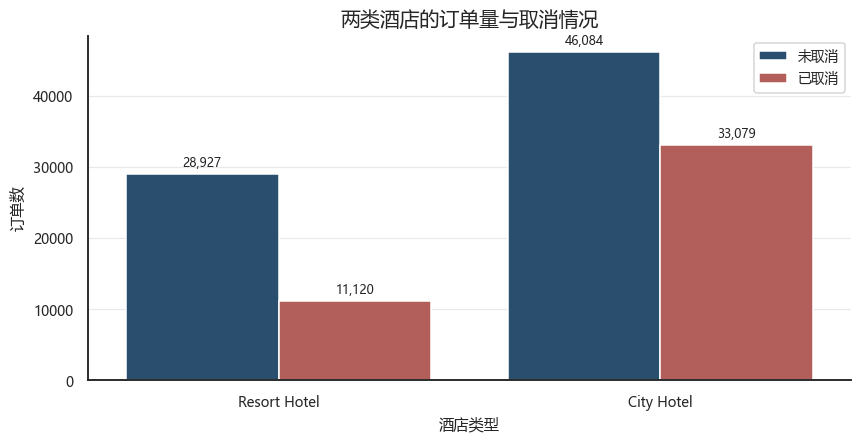

In [6]:
# ============================================================
# 5.1 两类酒店的订单量与取消情况
# ============================================================
fig, ax = plt.subplots(figsize=(8, 4.2))
ax = sns.countplot(
    data=df, x="hotel", hue="is_canceled",
    palette=[PALETTE["navy"], PALETTE["coral"]], ax=ax,
)
ax.set_title("两类酒店的订单量与取消情况")
ax.set_xlabel("酒店类型")
ax.set_ylabel("订单数")
ax.legend(title="", labels=["未取消", "已取消"])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v):,}" for v in container.datavalues], padding=3, fontsize=8)
style_ax(ax)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

,订单量,取消量,取消率(%),提前期中位数,住宿晚数中位数,ADR中位数
hotel,,,,,,
City Hotel,79163,33079,41.790000,74.000000,3.000000,99.960000
Resort Hotel,40047,11120,27.770000,57.000000,3.000000,75.000000


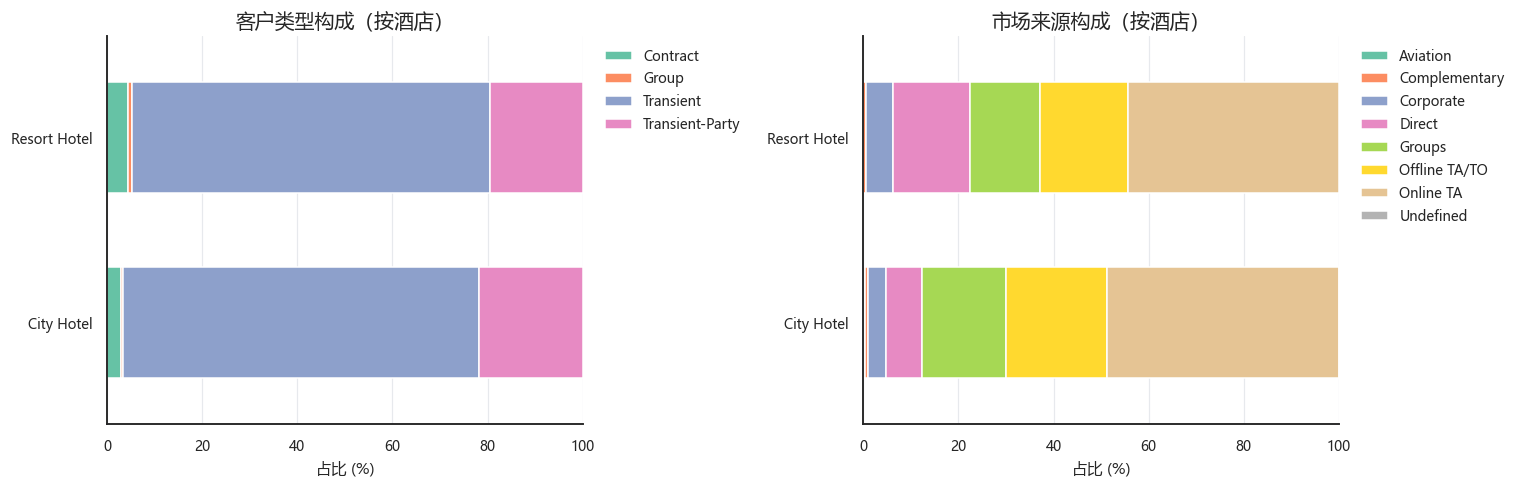

In [7]:
# 1. 酒店基本信息汇总
summary = df.groupby("hotel").agg(
    订单量=("is_canceled", "size"),
    取消量=("is_canceled", "sum"),
    取消率=("is_canceled", "mean"),
    提前期中位数=("lead_time", "median"),
    住宿晚数中位数=("total_nights", "median"),
    ADR中位数=("adr", "median"),
)
summary["取消率"] *= 100
summary = summary.rename(columns={"取消率": "取消率(%)"})
display(summary.round(2).style.set_caption("两类酒店基本画像"))

# 2. 客户类型、市场来源占比
features = {"customer_type": "客户类型", "market_segment": "市场来源"}
comps = {
    col: pd.crosstab(df["hotel"], df[col], normalize="index") * 100
    for col in features
}

# 3. 横向 100% 堆叠柱状图：比较两家酒店的构成差异
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (col, title) in zip(axes, features.items()):
    comp = comps[col]
    comp.plot.barh(
        stacked=True, ax=ax, width=0.6,
        color=sns.color_palette("Set2", comp.shape[1]),
    )
    ax.set_title(f"{title}构成（按酒店）")
    ax.set_xlabel("占比 (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    style_ax(ax, axis="x")
plt.tight_layout()
plt.show()

**分析结果：** 城市酒店订单更多，取消率也更高：**41.8% 对 27.8%**。两类酒店的客户类型和渠道构成存在差异，后续分开查看各酒店的渠道与季节表现。


### 6.2 时间变化与季节性

按**计划入住月份**汇总预订量、取消率和订单名义房费，并比较两类酒店在四季中的表现。


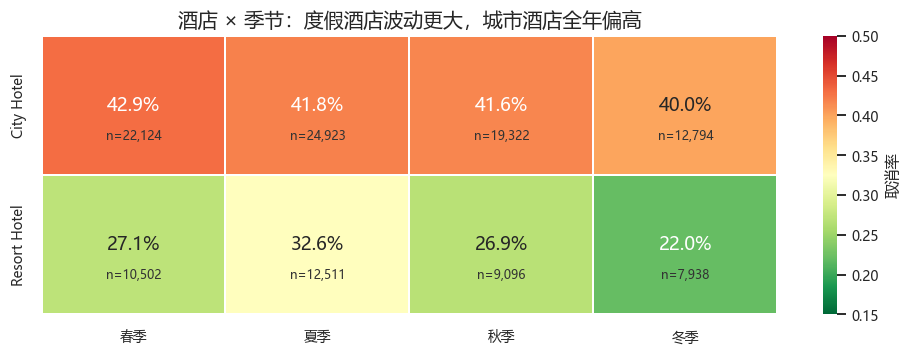

In [8]:
# ============================================================
# 5.2 酒店 × 季节：取消率热力图
# ============================================================
season_order = ["春季", "夏季", "秋季", "冬季"]
hotel_season = (
    df.pivot_table(index="hotel", columns="season", values="is_canceled", aggfunc="mean")
    .reindex(columns=season_order)
)
hotel_season_n = (
    df.pivot_table(index="hotel", columns="season", values="is_canceled", aggfunc="size")
    .reindex(columns=season_order)
)

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(
    hotel_season, annot=True, fmt=".1%", cmap="RdYlGn_r", vmin=0.15, vmax=0.50,
    linewidths=1, linecolor="white", cbar_kws={"label": "取消率"}, ax=ax,
)
for i, hotel in enumerate(hotel_season.index):
    for j, season in enumerate(season_order):
        ax.text(j + 0.5, i + 0.72, f"n={hotel_season_n.loc[hotel, season]:,}",
                ha="center", va="center", fontsize=8, color="#333333")
ax.set_title("酒店 × 季节：度假酒店波动更大，城市酒店全年偏高")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(
    df.groupby(["hotel", "season"], observed=True)["is_canceled"]
    .agg(预订数="size", 取消率="mean")
    .style.format({"预订数": "{:,}", "取消率": "{:.1%}"})
)

In [ ]:
# ============================================================
# 5.2 月度预订量、取消率与收入风险
# ============================================================
monthly = (
    df.assign(
        canceled_revenue=df["revenue"] * df["is_canceled"],
        noncanceled_revenue=df["revenue"] * (1 - df["is_canceled"]),
    )
    .groupby(df["arrival_date"].dt.to_period("M"))
    .agg(
        预订数=("is_canceled", "size"),
        取消率=("is_canceled", "mean"),
        未取消订单名义房费=("noncanceled_revenue", "sum"),
        取消订单名义房费=("canceled_revenue", "sum"),
    )
)
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(
    2, 1, figsize=(14, 7.4), sharex=True,
    gridspec_kw={"height_ratios": [1.25, 1]},
)

ax = axes[0]
ax.bar(monthly.index, monthly["预订数"], width=20, color=PALETTE["light"], label="预订数")
ax.set_ylabel("预订数")
ax.set_title("按入住月统计：预订量、取消率与名义房费")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["取消率"] * 100, color=PALETTE["coral"],
         marker="o", markersize=4, linewidth=2, label="取消率")
ax2.set_ylabel("取消率 (%)")
ax2.set_ylim(15, 55)
ax2.grid(False)
for x, y in zip(monthly.index, monthly["取消率"] * 100):
    ax2.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 7),
                 ha="center", fontsize=8, color=PALETTE["coral"])
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)
ax.set_ylim(0, monthly["预订数"].max() * 1.35)
style_ax(ax)

ax = axes[1]
ax.bar(monthly.index, monthly["未取消订单名义房费"] / 1e6, width=20,
       color=PALETTE["navy"], label="未取消订单名义房费")
ax.bar(monthly.index, monthly["取消订单名义房费"] / 1e6, width=20,
       bottom=monthly["未取消订单名义房费"] / 1e6, color=PALETTE["coral"], alpha=0.9,
       label="取消订单名义房费")
ax.set_ylabel("名义房费（百万；ADR × 晚数）")
ax.set_xlabel("入住月份")
ax.legend(loc="upper left", ncol=2, frameon=True)
ax.set_title(
    "2015-07 至 2017-08：取消订单名义房费约 {:.2f} 百万".format(
        df.loc[df.is_canceled == 1, "revenue"].sum() / 1e6
    )
)
style_ax(ax)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(
    monthly.tail(8).style.format({
        "预订数": "{:,.0f}", "取消率": "{:.1%}",
        "未取消订单名义房费": "{:,.0f}", "取消订单名义房费": "{:,.0f}",
    })
)

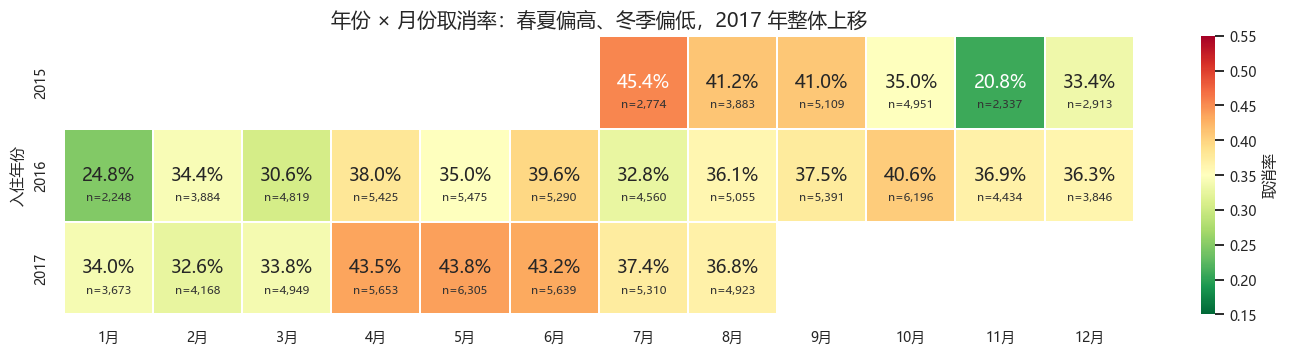

In [10]:
# ============================================================
# 5.2 年份 × 月份取消率（空白表示该月无数据）
# ============================================================
pivot_rate = df.pivot_table(
    index="arrival_date_year", columns="arrival_month_num",
    values="is_canceled", aggfunc="mean",
)
pivot_n = df.pivot_table(
    index="arrival_date_year", columns="arrival_month_num",
    values="is_canceled", aggfunc="size",
)
month_names = [f"{m}月" for m in range(1, 13)]
pivot_rate.columns = [month_names[c - 1] for c in pivot_rate.columns]

fig, ax = plt.subplots(figsize=(13, 3.4))
sns.heatmap(
    pivot_rate, annot=True, fmt=".1%", cmap="RdYlGn_r", vmin=0.15, vmax=0.55,
    linewidths=1, linecolor="white", cbar_kws={"label": "取消率"}, ax=ax,
)
for i, year in enumerate(pivot_rate.index):
    for j, _ in enumerate(pivot_rate.columns):
        n = pivot_n.loc[year, j + 1]
        if pd.notna(n):
            ax.text(j + 0.5, i + 0.74, f"n={int(n):,}", ha="center", va="center",
                    fontsize=7.5, color="#333333")
ax.set_title("年份 × 月份取消率：春夏偏高、冬季偏低，2017 年整体上移")
ax.set_xlabel("")
ax.set_ylabel("入住年份")
plt.tight_layout()
plt.show()

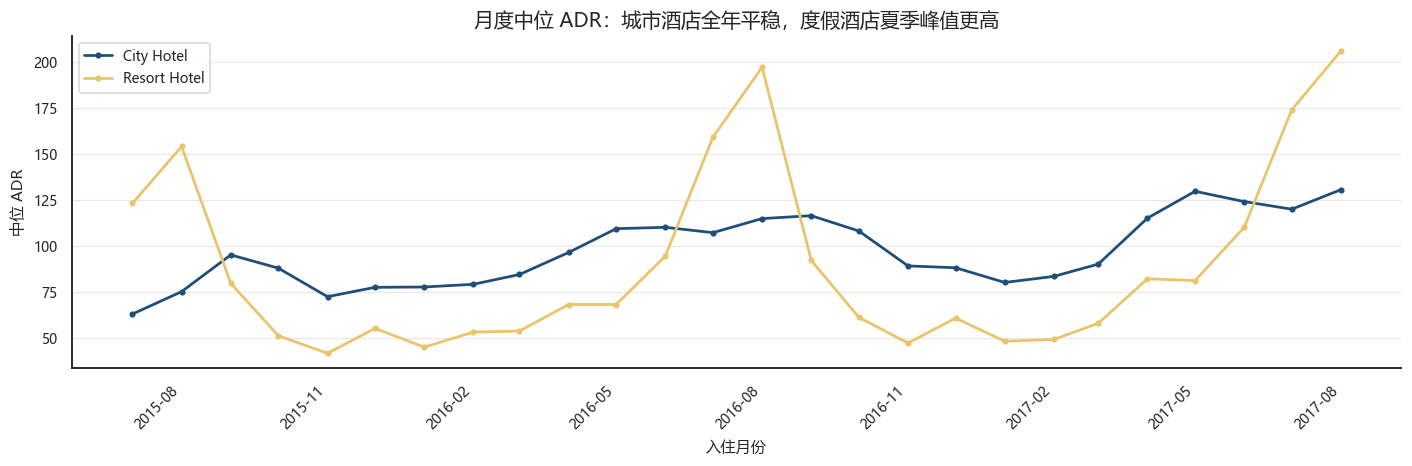

In [11]:
# ============================================================
# 5.2 月度中位 ADR：价格趋势
# ============================================================
adr_month = (
    df.groupby([df["arrival_date"].dt.to_period("M"), "hotel"])["adr"]
    .median()
    .unstack()
)
adr_month.index = adr_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 4.4))
for hotel, color in [("City Hotel", PALETTE["navy"]), ("Resort Hotel", PALETTE["gold"])]:
    ax.plot(adr_month.index, adr_month[hotel], marker="o", markersize=3,
            linewidth=1.8, color=color, label=hotel)
ax.set_title("月度中位 ADR：城市酒店全年平稳，度假酒店夏季峰值更高")
ax.set_ylabel("中位 ADR")
ax.set_xlabel("入住月份")
ax.legend(title="")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
style_ax(ax)
plt.tight_layout()
plt.show()

**分析结果**

- 夏季取消率 **38.8%**，冬季 **33.1%**。度假酒店在不同季节间的变化更明显（约 **22%–33%**）；城市酒店各季节保持在约 **40%–43%**。
- 从入住月份看，2016 年的月度记录覆盖完整，可用于观察全年变化。
- 取消订单涉及约 **1,673 万**名义房费，占全部订单名义房费的 **39.2%**。后续用这一指标比较各渠道对应的订单金额规模。


### 6.3 预订提前期

按预订提前天数分组，比较订单量与取消率，并观察取消订单和未取消订单的提前期分布。


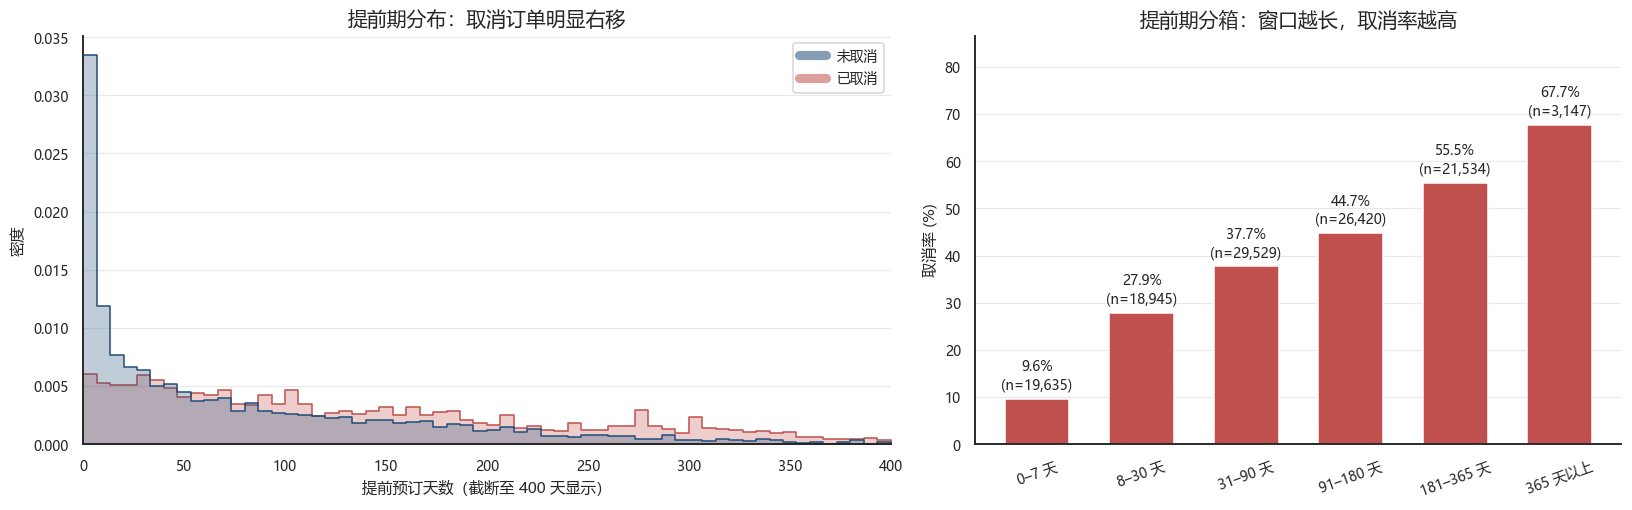

未取消订单提前期中位数：45 天
取消订单提前期中位数  ：113 天
提前 180 天以上订单的取消率：57.0%
提前 7 天内订单的取消率    ：9.6%


In [12]:
# ============================================================
# 5.3 提前期分布与分段取消率
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
sns.histplot(
    data=df, x="lead_time", hue="is_canceled", hue_order=[0, 1],
    bins=60, binrange=(0, 400), stat="density", common_norm=False,
    element="step", fill=True, alpha=0.28,
    palette={0: PALETTE["navy"], 1: PALETTE["coral"]},
    legend=False, ax=ax,
)
ax.set_xlim(0, 400)
ax.set_xlabel("提前预订天数（截断至 400 天显示）")
ax.set_ylabel("密度")
ax.set_title("提前期分布：取消订单明显右移")
handles = [
    Line2D([], [], color=PALETTE["navy"], lw=6, alpha=0.55, label="未取消"),
    Line2D([], [], color=PALETTE["coral"], lw=6, alpha=0.55, label="已取消"),
]
ax.legend(handles=handles, title="", loc="upper right", frameon=True)
style_ax(ax)

ax = axes[1]
g = df.groupby("lead_time_bucket", observed=True)["is_canceled"].agg(["mean", "size"])
bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=PALETTE["coral"], width=0.62)
for bar, (_, row) in zip(bars, g.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
            f"{row['mean']:.1%}\n(n={int(row['size']):,})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, g["mean"].max() * 128)
ax.set_ylabel("取消率 (%)")
ax.set_title("提前期分箱：窗口越长，取消率越高")
ax.tick_params(axis="x", rotation=20)
style_ax(ax)
plt.tight_layout()
plt.show()

print(f"未取消订单提前期中位数：{df.loc[df.is_canceled == 0, 'lead_time'].median():.0f} 天")
print(f"取消订单提前期中位数  ：{df.loc[df.is_canceled == 1, 'lead_time'].median():.0f} 天")
print(f"提前 180 天以上订单的取消率：{df.loc[df.lead_time > 180, 'is_canceled'].mean():.1%}")
print(f"提前 7 天内订单的取消率    ：{df.loc[df.lead_time <= 7, 'is_canceled'].mean():.1%}")

### 6.4 房价与住宿时长

分别比较住宿晚数、入住人数和 ADR 分位组的取消率，观察不同订单金额与住宿安排的分布差异。


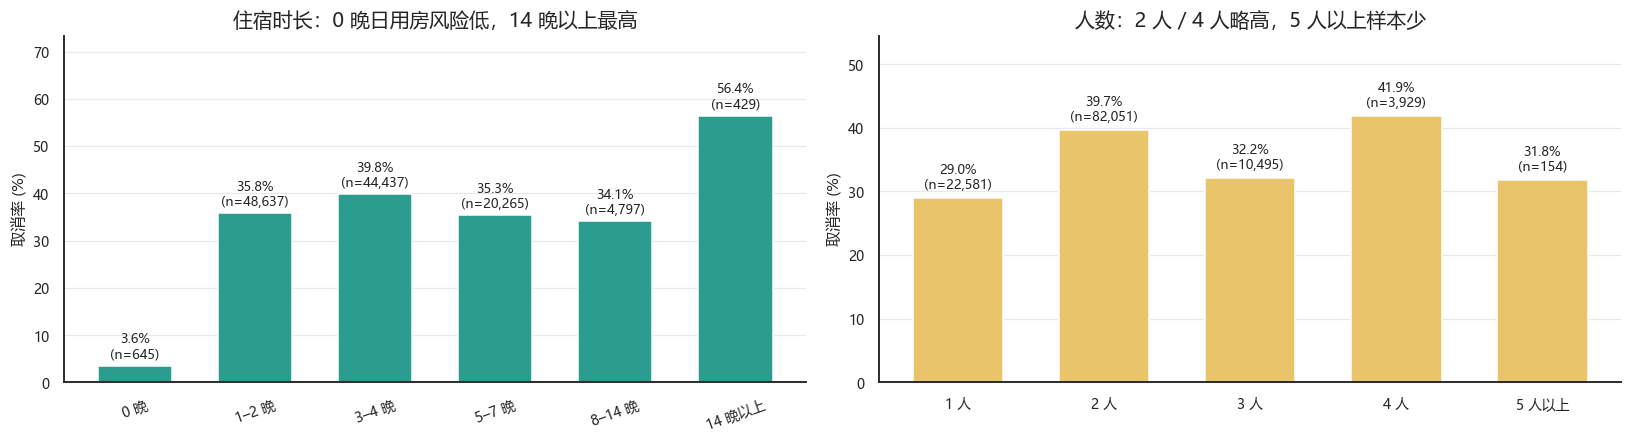

In [13]:
# ============================================================
# 5.4 住宿时长与人数
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

ax = axes[0]
g = df.groupby("stay_bucket", observed=True)["is_canceled"].agg(["mean", "size"])
bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=PALETTE["teal"], width=0.62)
for bar, (_, row) in zip(bars, g.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"{row['mean']:.1%}\n(n={int(row['size']):,})", ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, g["mean"].max() * 130)
ax.set_ylabel("取消率 (%)")
ax.set_title("住宿时长：0 晚日用房风险低，14 晚以上最高")
ax.tick_params(axis="x", rotation=20)
style_ax(ax)

ax = axes[1]
g = df.groupby("guest_bucket", observed=True)["is_canceled"].agg(["mean", "size"])
bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=PALETTE["gold"], width=0.62)
for bar, (_, row) in zip(bars, g.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"{row['mean']:.1%}\n(n={int(row['size']):,})", ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, max(g["mean"].max() * 130, 30))
ax.set_ylabel("取消率 (%)")
ax.set_title("人数：2 人 / 4 人略高，5 人以上样本少")
ax.tick_params(axis="x", rotation=0)
style_ax(ax)

plt.tight_layout()
plt.show()

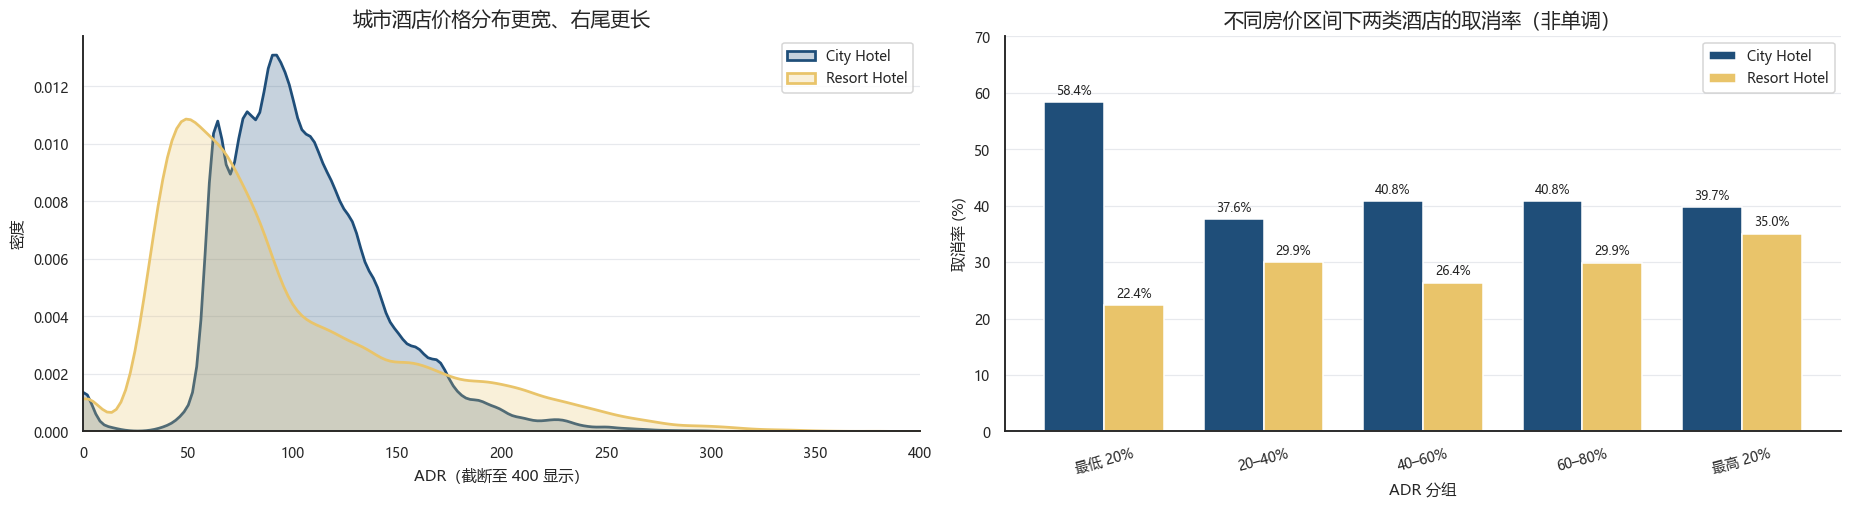

In [14]:
# ============================================================
# 5.4 房价分布、分段取消率
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))

ax = axes[0]
for hotel, color in zip(["City Hotel", "Resort Hotel"], [PALETTE["navy"], PALETTE["gold"]]):
    subset = df.loc[(df.hotel == hotel) & (df.adr <= 400), "adr"]
    sns.kdeplot(subset, ax=ax, color=color, fill=True, alpha=0.25, linewidth=1.8, label=hotel)
ax.set_xlim(0, 400)
ax.set_xlabel("ADR（截断至 400 显示）")
ax.set_ylabel("密度")
ax.set_title("城市酒店价格分布更宽、右尾更长")
ax.legend()
style_ax(ax)

ax = axes[1]
g = (
    df.groupby(["adr_bucket", "hotel"], observed=True)["is_canceled"]
    .mean()
    .unstack("hotel") * 100
)
g = g.reindex(columns=["City Hotel", "Resort Hotel"])
g.plot(kind="bar", ax=ax, width=0.75, rot=0,
       color=[PALETTE["navy"], PALETTE["gold"]])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)
ax.set_ylim(0, min(100, g.max().max() * 1.2))
ax.set_xlabel("ADR 分组")
ax.set_ylabel("取消率 (%)")
ax.set_title("不同房价区间下两类酒店的取消率（非单调）")
ax.legend(title="")
ax.tick_params(axis="x", rotation=15)
style_ax(ax)

plt.tight_layout()
plt.show()

**分析结果：** 取消率没有随着 ADR 分位组持续上升。城市酒店在各房价分组中的取消率整体更高。房价更适合与订单量、住宿晚数一起用于评估取消订单所涉及的金额规模。


### 6.5 渠道、客户类型与押金

分别统计市场细分、分销渠道、客户类型和押金类型的预订量与取消率，再把市场细分按**订单量、取消率、取消订单名义房费**放在一起比较。


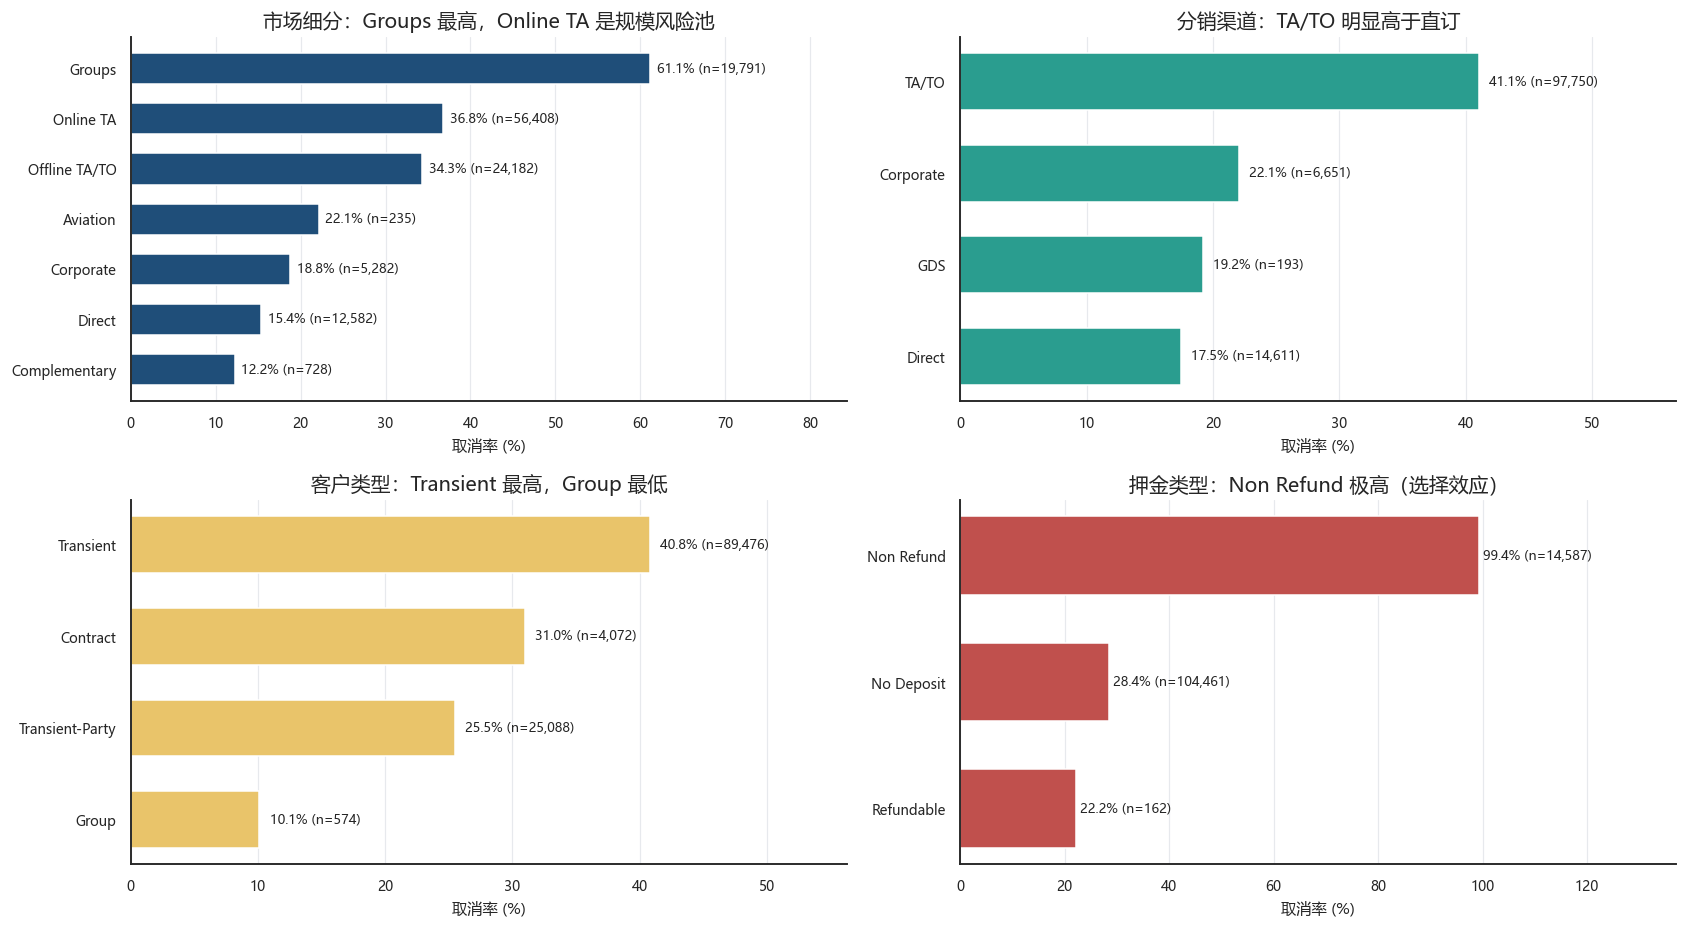

,预订数,取消数,取消率
deposit_type,,,
No Deposit,"104,461","29,669",28.40%
Non Refund,"14,587","14,494",99.36%
Refundable,162,36,22.22%


In [15]:
# ============================================================
# 5.5 市场细分、分销渠道、客户类型、押金
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15.5, 8.6))

def rate_bar(ax, col, title, color, min_n=50):
    g = df.groupby(col, observed=True)["is_canceled"].agg(["mean", "size"])
    g = g[g["size"] >= min_n].sort_values("mean")
    bars = ax.barh(g.index.astype(str), g["mean"] * 100, color=color, height=0.62)
    for bar, (_, row) in zip(bars, g.iterrows()):
        ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
                f"{row['mean']:.1%} (n={int(row['size']):,})", va="center", fontsize=8.5)
    ax.set_xlim(0, max(g["mean"].max() * 100 * 1.38, 20))
    ax.set_xlabel("取消率 (%)")
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=9)
    style_ax(ax, axis="x")

rate_bar(axes[0, 0], "market_segment", "市场细分：Groups 最高，Online TA 是规模风险池", PALETTE["navy"])
rate_bar(axes[0, 1], "distribution_channel", "分销渠道：TA/TO 明显高于直订", PALETTE["teal"])
rate_bar(axes[1, 0], "customer_type", "客户类型：Transient 最高，Group 最低", PALETTE["gold"])
rate_bar(axes[1, 1], "deposit_type", "押金类型：Non Refund 极高（选择效应）", PALETTE["coral"])

plt.tight_layout()
plt.show()

display(
    df.groupby("deposit_type")["is_canceled"]
    .agg(预订数="size", 取消数="sum", 取消率="mean")
    .style.format({"预订数": "{:,}", "取消数": "{:,}", "取消率": "{:.2%}"})
)

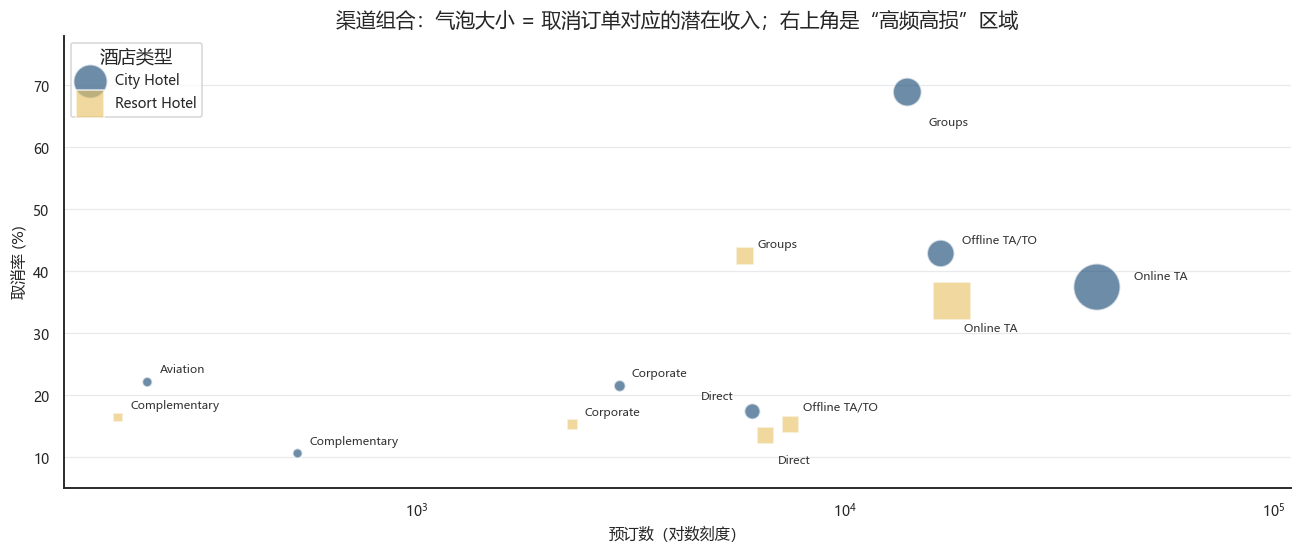

,预订数,取消率,取消收入,取消收入占比
market_segment,,,,
Online TA,"56,408",36.8%,"10,227,646",61.1%
Groups,"19,791",61.1%,"2,800,544",16.7%
Offline TA/TO,"24,182",34.3%,"2,492,358",14.9%
Direct,"12,582",15.4%,"993,410",5.9%
Corporate,"5,282",18.8%,"196,383",1.2%
Aviation,235,22.1%,"16,578",0.1%
Complementary,728,12.2%,270,0.0%
Undefined,2,100.0%,48,0.0%


In [16]:
# ============================================================
# 5.5 渠道组合：数量 × 取消率 × 收入风险
# ============================================================
seg = (
    df.assign(canceled_revenue=df["revenue"] * df["is_canceled"])
    .groupby(["market_segment", "hotel"], observed=True)
    .agg(预订数=("is_canceled", "size"),
         取消率=("is_canceled", "mean"),
         取消收入=("canceled_revenue", "sum"))
    .reset_index()
)
seg = seg[seg["预订数"] >= 50]

fig, ax = plt.subplots(figsize=(12, 5.2))
# 手动标注偏移，避免同细分两个酒店的标签互相遮挡
LABEL_OFFSET = {
    ("Groups", "City Hotel"): (14, -22),
    ("Direct", "City Hotel"): (-12, 8),
    ("Direct", "Resort Hotel"): (8, -18),
    ("Offline TA/TO", "City Hotel"): (14, 7),
    ("Offline TA/TO", "Resort Hotel"): (8, 10),
    ("Online TA", "City Hotel"): (24, 5),
    ("Online TA", "Resort Hotel"): (8, -20),
}
for hotel, color, marker in [("City Hotel", PALETTE["navy"], "o"),
                             ("Resort Hotel", PALETTE["gold"], "s")]:
    sub = seg[seg.hotel == hotel]
    sizes = 40 + sub["取消收入"] / seg["取消收入"].max() * 900
    ax.scatter(sub["预订数"], sub["取消率"] * 100, s=sizes, color=color, alpha=0.65,
               edgecolor="white", linewidth=1.2, label=hotel, marker=marker)
    for _, row in sub.iterrows():
        dx, dy = LABEL_OFFSET.get((row["market_segment"], hotel), (8, 6))
        ax.annotate(
            row["market_segment"], (row["预订数"], row["取消率"] * 100),
            textcoords="offset points", xytext=(dx, dy), fontsize=7.5, color="#333333",
            ha="right" if dx < 0 else "left",
        )
ax.set_xscale("log")
ax.set_xlim(150, 110000)
ax.set_ylim(5, 78)
ax.set_xlabel("预订数（对数刻度）")
ax.set_ylabel("取消率 (%)")
ax.set_title("渠道组合：气泡大小 = 取消订单对应的潜在收入；右上角是“高频高损”区域")
ax.legend(title="酒店类型", loc="upper left")
style_ax(ax)
plt.tight_layout()
plt.show()

risk_table = (
    df.assign(canceled_revenue=df["revenue"] * df["is_canceled"])
    .groupby("market_segment", observed=True)
    .agg(预订数=("is_canceled", "size"),
         取消率=("is_canceled", "mean"),
         取消收入=("canceled_revenue", "sum"))
    .sort_values("取消收入", ascending=False)
)
risk_table["取消收入占比"] = risk_table["取消收入"] / risk_table["取消收入"].sum()
display(risk_table.style.format({
    "预订数": "{:,}", "取消率": "{:.1%}", "取消收入": "{:,.0f}",
    "取消收入占比": "{:.1%}",
}))

**分析结果**

- **Groups：** 市场细分中的取消率为 **61.1%**，是各主要细分中较高的一组。
- **Online TA：** 取消率为 **36.8%**，但订单规模大，贡献约 **61.1%** 的取消订单名义房费，是重点关注的线上渠道。
- **Direct / Corporate：** 取消率分别为 **15.4% / 18.8%**，明显低于 Online TA。
- **Non Refund：** 该押金类型的取消率达到 **99.4%**，是值得进一步拆分研究的异常分组。
- **客户类型：** `customer_type=Transient` 取消率为 **40.8%**，`customer_type=Group` 为 **10.1%**；与 `market_segment=Groups` 的分组结果不同。



### 6.6 客源国

比较主要客源国的订单占比、取消率及取消订单名义房费，识别订单规模较大的客源市场。


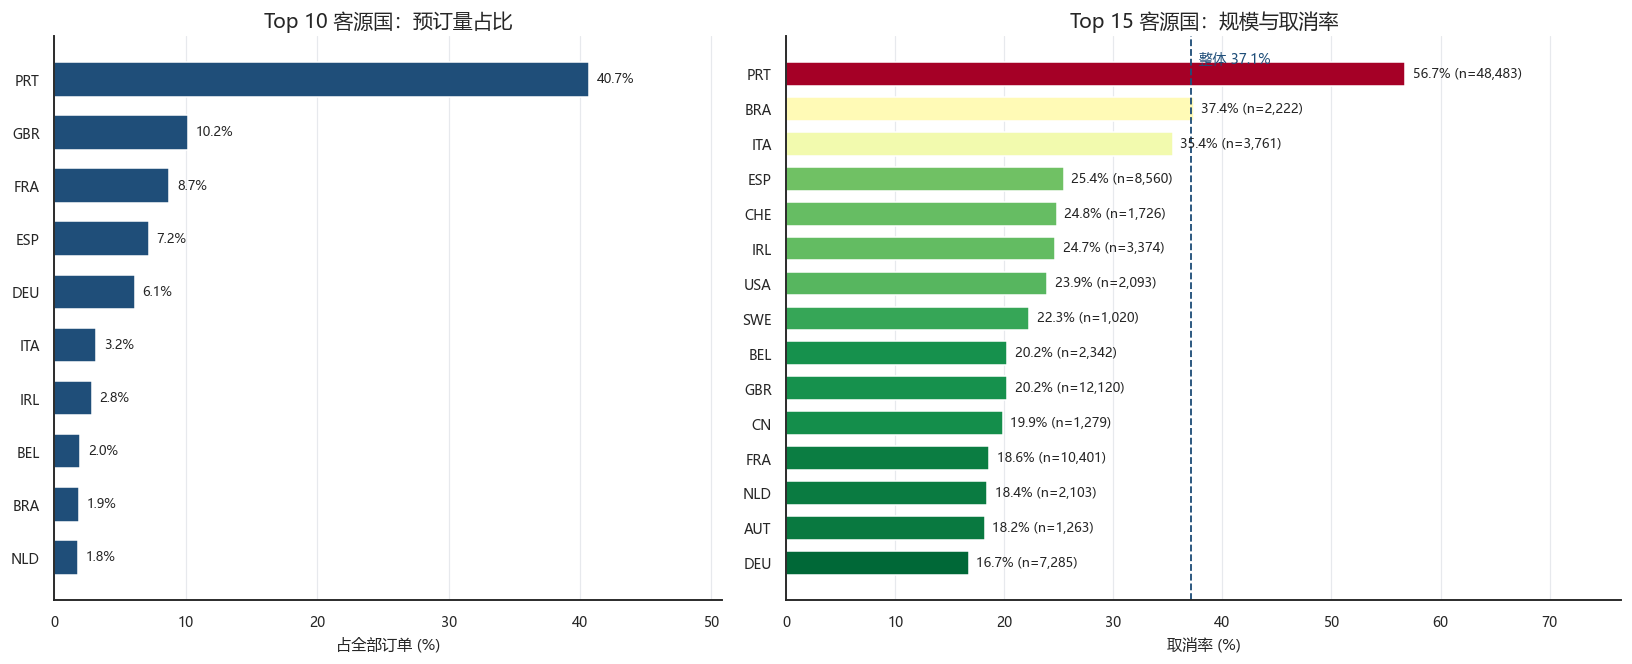

Top 10 客源国的取消收入风险：


,预订数,取消率,取消收入
country,,,
PRT,"48,483",56.7%,"8,586,002"
GBR,"12,120",20.2%,"1,172,172"
ESP,"8,560",25.4%,"1,057,329"
FRA,"10,401",18.6%,"927,817"
DEU,"7,285",16.7%,"556,243"
ITA,"3,761",35.4%,"550,432"
IRL,"3,374",24.7%,"412,098"
BRA,"2,222",37.4%,"386,225"
AGO,362,56.6%,"273,117"


In [17]:
# ============================================================
# 5.6 Top 客源国：规模、取消率与收入风险
# ============================================================
country_stats = (
    df.groupby("country")
    .agg(
        预订数=("is_canceled", "size"),
        取消率=("is_canceled", "mean"),
        取消收入=("revenue", lambda s: s[df.loc[s.index, "is_canceled"] == 1].sum()),
    )
    .query("预订数 >= 100")
)
top_volume = country_stats.sort_values("预订数", ascending=False).head(10)
top_rate = country_stats.sort_values("预订数", ascending=False).head(15).sort_values("取消率")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
share = top_volume["预订数"] / len(df) * 100
bars = ax.barh(top_volume.index[::-1], share[::-1], color=PALETTE["navy"], height=0.65)
for bar, value in zip(bars, share[::-1]):
    ax.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%", va="center", fontsize=8.5)
ax.set_xlim(0, share.max() * 1.25)
ax.set_xlabel("占全部订单 (%)")
ax.set_title("Top 10 客源国：预订量占比")
style_ax(ax, axis="x")

ax = axes[1]
norm = mpl.colors.Normalize(vmin=top_rate["取消率"].min(), vmax=top_rate["取消率"].max())
colors = plt.cm.RdYlGn_r(norm(top_rate["取消率"]))
bars = ax.barh(top_rate.index, top_rate["取消率"] * 100, color=colors, height=0.68)
for bar, (_, row) in zip(bars, top_rate.iterrows()):
    ax.text(bar.get_width() + 0.7, bar.get_y() + bar.get_height() / 2,
            f"{row['取消率']:.1%} (n={int(row['预订数']):,})", va="center", fontsize=8.5)
overall = df["is_canceled"].mean() * 100
ax.axvline(overall, color=PALETTE["navy"], linestyle="--", linewidth=1.2)
ax.text(overall + 0.8, len(top_rate) - 0.35, f"整体 {overall:.1f}%",
        color=PALETTE["navy"], fontsize=9, va="top")
ax.set_xlim(0, top_rate["取消率"].max() * 100 * 1.35)
ax.set_xlabel("取消率 (%)")
ax.set_title("Top 15 客源国：规模与取消率")
style_ax(ax, axis="x")

plt.tight_layout()
plt.show()

print("Top 10 客源国的取消收入风险：")
display(
    country_stats.sort_values("取消收入", ascending=False).head(10)
    .style.format({"预订数": "{:,}", "取消率": "{:.1%}", "取消收入": "{:,.0f}"})
)

**分析结果：** 葡萄牙（PRT）约占全部订单的 **40.7%**，取消率 **56.7%**，既是最大客源市场，也是取消订单集中的市场之一。后续可以优先对 PRT、GBR、FRA、ESP 等主要客源国按酒店和渠道进一步拆分。


### 6.7 客户预订行为

查看特殊请求数量、预订修改次数、历史取消次数和等待名单天数的分组取消率。


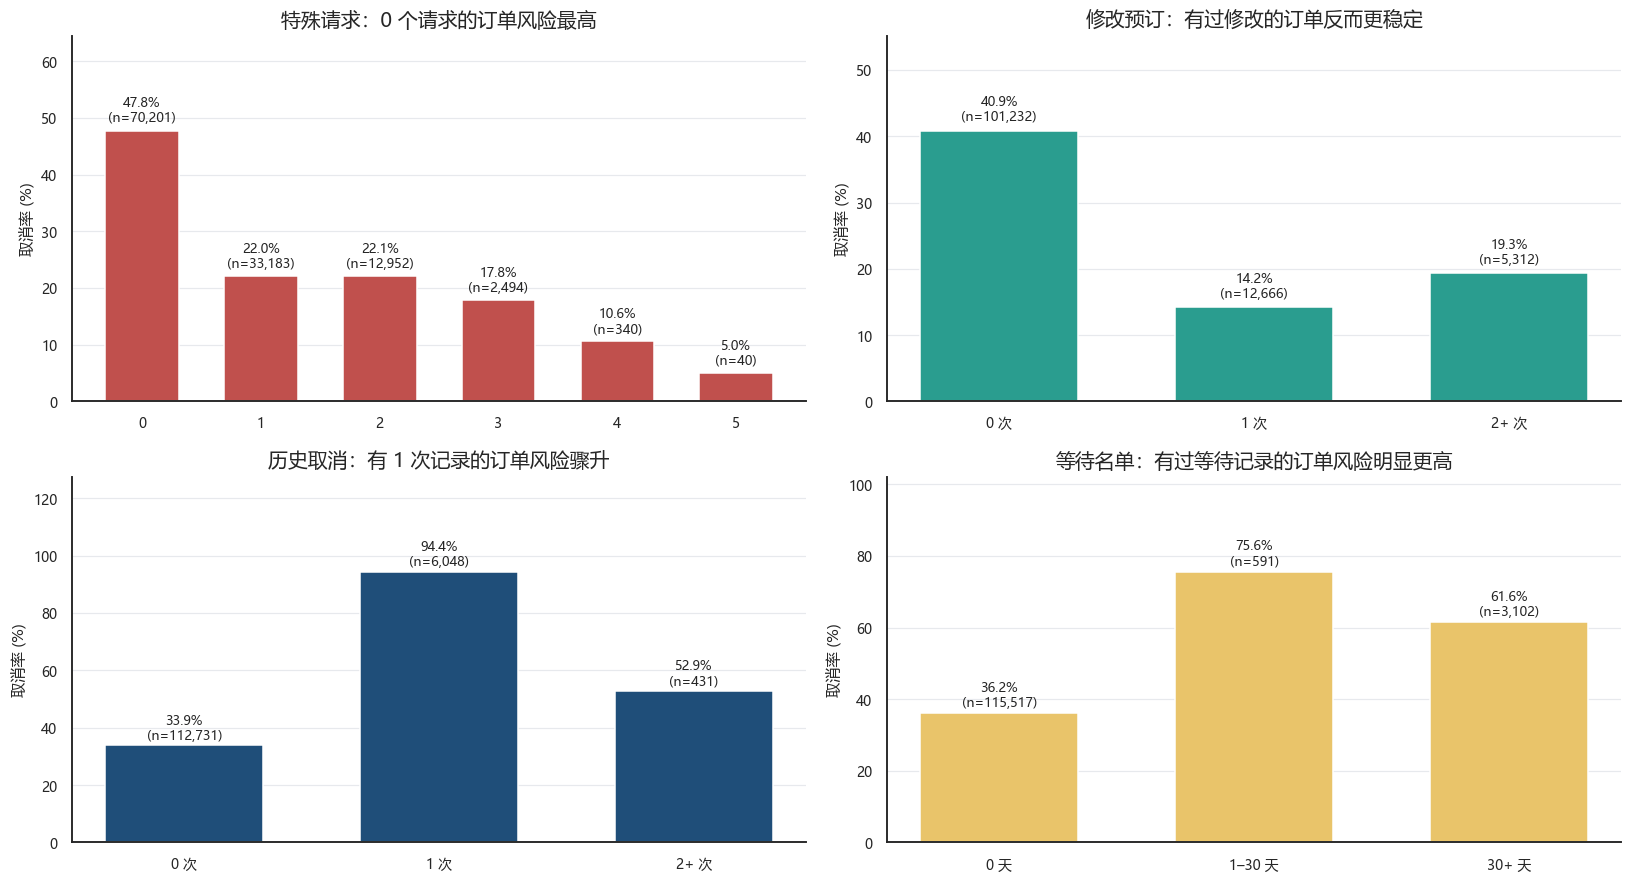

特殊请求数与取消率的完整对照：


,预订数,取消率
total_of_special_requests,,
0,"70,201",47.8%
1,"33,183",22.0%
2,"12,952",22.1%
3,"2,494",17.8%
4,340,10.6%
5,40,5.0%


In [18]:
# ============================================================
# 5.7 特殊请求、修改次数、历史取消、等待名单
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 8.2))

def grouped_rate(ax, series, title, color, order=None):
    g = df.groupby(series, observed=True)["is_canceled"].agg(["mean", "size"])
    if order is not None:
        g = g.reindex(order)
    g = g[g["size"] > 0]
    bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=color, width=0.62)
    for bar, (_, row) in zip(bars, g.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                f"{row['mean']:.1%}\n(n={int(row['size']):,})", ha="center", va="bottom", fontsize=8.5)
    ax.set_ylim(0, max(g["mean"].max() * 135, 25))
    ax.set_ylabel("取消率 (%)")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=0)
    style_ax(ax)

grouped_rate(axes[0, 0], df["total_of_special_requests"],
             "特殊请求：0 个请求的订单风险最高", PALETTE["coral"])
grouped_rate(
    axes[0, 1],
    df["booking_changes"].clip(upper=2).map({0: "0 次", 1: "1 次", 2: "2+ 次"}),
    "修改预订：有过修改的订单反而更稳定", PALETTE["teal"],
    order=["0 次", "1 次", "2+ 次"],
)
grouped_rate(
    axes[1, 0],
    df["previous_cancellations"].clip(upper=2).map({0: "0 次", 1: "1 次", 2: "2+ 次"}),
    "历史取消：有 1 次记录的订单风险骤升", PALETTE["navy"],
    order=["0 次", "1 次", "2+ 次"],
)
grouped_rate(
    axes[1, 1],
    df["days_in_waiting_list"].clip(upper=31).map(
        lambda x: "0 天" if x == 0 else ("1–30 天" if x <= 30 else "30+ 天")
    ),
    "等待名单：有过等待记录的订单风险明显更高", PALETTE["gold"],
    order=["0 天", "1–30 天", "30+ 天"],
)
plt.tight_layout()
plt.show()

print("特殊请求数与取消率的完整对照：")
display(
    df.groupby("total_of_special_requests")["is_canceled"]
    .agg(预订数="size", 取消率="mean")
    .style.format({"预订数": "{:,}", "取消率": "{:.1%}"})
)

**分析结果**

- **特殊请求：** 0 个请求的订单取消率为 **47.8%**；1 个请求为 **22.0%**，2 个为 **22.1%**，3 个及以上约 **16.8%**。
- **预订修改：** 未修改订单取消率 **40.9%**；修改过 1 次为 **14.2%**，修改过 2 次及以上约 **19.3%**。
- **历史取消：** 有过 1 次取消记录的订单，当前取消率约 **94.4%**；有 2 次及以上记录的分组约 **52.9%**。
- **等待名单：** 等待 1–30 天的订单取消率约 **75.6%**，等待 30 天以上约 **61.6%**。

特殊请求与预订修改情况呈现出明显的分组差异，适合加入后续的订单分层监控。


### 6.8 数值变量相关性

使用 Spearman 相关矩阵汇总取消状态与提前期、ADR、住宿晚数、历史行为等变量的关系，辅助筛选值得重点观察的指标。


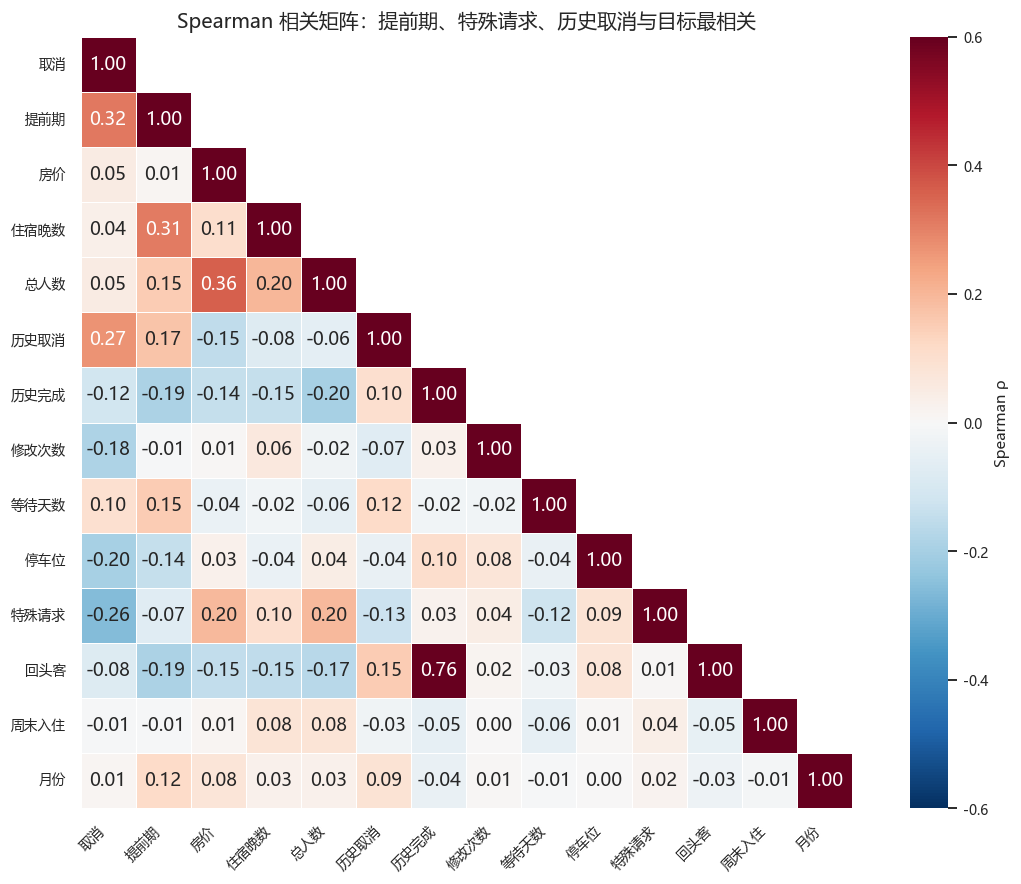

与取消相关性的绝对值排序：


,Spearman ρ
提前期,+0.316
历史取消,+0.270
特殊请求,-0.259
停车位,-0.198
修改次数,-0.184
历史完成,-0.115
等待天数,+0.098
回头客,-0.084
总人数,+0.050
房价,+0.050


In [19]:
# ============================================================
# 5.8 Spearman 相关矩阵
# ============================================================
corr_cols = [
    "is_canceled", "lead_time", "adr", "total_nights", "total_guests",
    "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests",
    "is_repeated_guest", "is_weekend_arrival", "arrival_month_num",
]
corr_labels = {
    "is_canceled": "取消", "lead_time": "提前期", "adr": "房价", "total_nights": "住宿晚数",
    "total_guests": "总人数", "previous_cancellations": "历史取消",
    "previous_bookings_not_canceled": "历史完成", "booking_changes": "修改次数",
    "days_in_waiting_list": "等待天数", "required_car_parking_spaces": "停车位",
    "total_of_special_requests": "特殊请求", "is_repeated_guest": "回头客",
    "is_weekend_arrival": "周末入住", "arrival_month_num": "月份",
}
corr = df[corr_cols].rename(columns=corr_labels).corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-0.6, vmax=0.6, square=True, linewidths=0.6, linecolor="white",
    cbar_kws={"label": "Spearman ρ"}, ax=ax,
)
ax.set_title("Spearman 相关矩阵：提前期、特殊请求、历史取消与目标最相关")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

target_corr = corr["取消"].drop("取消").sort_values(key=np.abs, ascending=False)
print("与取消相关性的绝对值排序：")
display(target_corr.to_frame("Spearman ρ").style.format("{:+.3f}").background_gradient(
    cmap="RdBu_r", vmin=-0.6, vmax=0.6
))

## 7. 分析结论与运营建议

### 7.1 重点关注的订单与渠道

综合**取消率、订单规模、取消订单名义房费**三个维度，得到以下优先级：

1. **Online TA：** 对应约 61.1% 的取消订单名义房费，适合作为渠道层面监控的第一重点。
2. **城市酒店：** 订单量大、取消率 **41.8%**，可重点监控旺季库存和临近入住的取消情况。
3. **长提前期订单：** 提前 180 天以上取消率 **57.0%**，值得在入住前增加确认与改期选项。
4. **Groups：** 取消率 **61.1%**，可以单独建立团队订单的确认和管理流程。
5. **无特殊请求、历史有取消记录的订单：** 可作为下一步组合分层和精细化运营的候选指标。

### 7.2 建议的运营动作

| 对象 | 建议动作 | 观察指标 |
|---|---|---|
| Online TA、长提前期订单 | 分批开展入住前确认，提供改期选项 | 确认回复率、最终取消率 |
| 城市酒店旺季订单 | 监控临近入住的取消情况，提前调整库存预案 | 临近取消率、房间空置情况 |
| Groups 团队订单 | 单独设置团队订单确认节点 | 团队订单取消率、取消时点 |
| 不同客源国和渠道 | 按酒店类型建立分组监控表 | 分组订单量、取消率 |
| 有历史取消记录的客户 | 纳入重点订单复核范围 | 复核覆盖率、最终取消率 |



## 8. 附录：数据口径

### 项目目录

```text
hotel-booking-cancellation-eda/
├── README.md
├── requirements.txt
├── notebooks/
│   └── hotel_booking_cancellation_eda.ipynb
├── assets/
└── data/
    └── README.md
```

### 指标口径

| 指标 | 定义 |
|---|---|
| 取消率 | 取消记录数 / 该分组记录数 |
| 住宿晚数 | `stays_in_weekend_nights + stays_in_week_nights` |
| 订单名义房费 | `adr × 住宿晚数` |
| 取消订单名义房费占比 | 取消订单名义房费总额 / 全部订单名义房费总额 |

**样本量：** 原始 119,390 条；剔除零客人记录后 119,210 条；其中零晚住宿记录 645 条。
